In [1]:
import re
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer

In [2]:
docs = [
    "The cat sat on the mat",
    "The dog sat on the log",
    "The cat and the dog are friends",
    "Dogs and cats are pets",
]
for i, d in enumerate(docs): print(f"D{i+1}: {d}")

D1: The cat sat on the mat
D2: The dog sat on the log
D3: The cat and the dog are friends
D4: Dogs and cats are pets


In [3]:
def tokenize(t):
    return re.findall(r"(?u)\b\w\w+\b", t.lower())

vocab = sorted({w for d in docs for w in tokenize(d)})
word2idx = {w: i for i, w in enumerate(vocab)}

bow = np.zeros((len(docs), len(vocab)), dtype=int)
for i, d in enumerate(docs):
    for w in tokenize(d):
        bow[i, word2idx[w]] += 1

df_manual = pd.DataFrame(bow, columns=vocab, index=[f"D{i+1}" for i in range(len(docs))])
print("Vocabulary size:", len(vocab))
df_manual

Vocabulary size: 13


,and,are,cat,cats,dog,dogs,friends,log,mat,on,pets,sat,the
D1,0,0,1,0,0,0,0,0,1,1,0,1,2
D2,0,0,0,0,1,0,0,1,0,1,0,1,2
D3,1,1,1,0,1,0,1,0,0,0,0,0,2
D4,1,1,0,1,0,1,0,0,0,0,1,0,0


In [4]:
cv = CountVectorizer()
X = cv.fit_transform(docs)
df_sk = pd.DataFrame(X.toarray(), columns=cv.get_feature_names_out(), index=df_manual.index)
print("Manual BoW == sklearn BoW :", np.array_equal(df_manual.values, df_sk.values))
df_sk

Manual BoW == sklearn BoW : True


,and,are,cat,cats,dog,dogs,friends,log,mat,on,pets,sat,the
D1,0,0,1,0,0,0,0,0,1,1,0,1,2
D2,0,0,0,0,1,0,0,1,0,1,0,1,2
D3,1,1,1,0,1,0,1,0,0,0,0,0,2
D4,1,1,0,1,0,1,0,0,0,0,1,0,0


In [5]:
print("Binary BoW:")
display(pd.DataFrame(CountVectorizer(binary=True).fit_transform(docs).toarray(),
                     columns=cv.get_feature_names_out()))

cv_stop = CountVectorizer(stop_words="english")
print("\nAfter stop-word removal:", cv_stop.fit(docs).get_feature_names_out())

cv_bi = CountVectorizer(ngram_range=(1, 2))
cv_bi.fit(docs)
print("\nUnigrams + bigrams vocabulary size:", len(cv_bi.vocabulary_))

Binary BoW:


,and,are,cat,cats,dog,dogs,friends,log,mat,on,pets,sat,the
0,0,0,1,0,0,0,0,0,1,1,0,1,1
1,0,0,0,0,1,0,0,1,0,1,0,1,1
2,1,1,1,0,1,0,1,0,0,0,0,0,1
3,1,1,0,1,0,1,0,0,0,0,1,0,0



After stop-word removal: ['cat' 'cats' 'dog' 'dogs' 'friends' 'log' 'mat' 'pets' 'sat']

Unigrams + bigrams vocabulary size: 29


{'and': 0, 'are': 0, 'cat': 1, 'cats': 0, 'dog': 1, 'dogs': 0, 'friends': 0, 'log': 0, 'mat': 0, 'on': 0, 'pets': 0, 'sat': 0, 'the': 2}


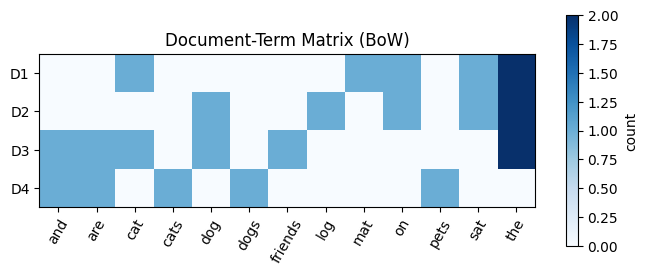

In [6]:
import matplotlib.pyplot as plt
new = ["The cat chased the dog"]
print(dict(zip(cv.get_feature_names_out(), cv.transform(new).toarray()[0].tolist())))

plt.figure(figsize=(8, 3))
plt.imshow(df_sk.values, cmap="Blues")
plt.xticks(range(len(vocab)), vocab, rotation=60); plt.yticks(range(len(docs)), df_sk.index)
plt.colorbar(label="count"); plt.title("Document-Term Matrix (BoW)"); plt.show()